# 05 · 误差分析

最终模型之后，检查误差还剩在哪里，并记录试过但没有采用的方法：

1. **最终模型的残差**：哪些分组仍有系统偏差？大误差来自哪里？
2. **残差的结构 → 第二层**：同一运动员、同一场比赛的残差相关，双胞胎；5 种平滑做法的比较。之后的成对平滑在 04 第 5 节。
3. **数据清洗实验**：训练时去掉疑似错误的成绩，会不会更好？
4. **没有成功的方向**。
5. **交叉验证与公开榜**：两者是否一致，公开榜有多大噪声。

本 notebook 只读取 02–04 保存的结果，不训练，也不需要 GPU。

| notebook | 内容 |
|---|---|
| **01_data_exploration** | 读取与核对原始数据、探索分析、记录精度与「双胞胎」、数据质量检查、固定五折 |
| **02_feature_engineering** | 四轮特征（记录精度、跨地参赛、比赛背景、运动员历史与生涯、基于成绩的特征）及五折消融（实验 07、09、10、14） |
| **03_model_selection** | 早期基线、CatBoost 参数、其他模型与相对力量目标、堆叠方式、目标变量工程、模型大比较（实验 08、13） |
| **04_final_model** | 最终集成：8 个模型 × 5 折 × 3 种子 + 全量重训、NNLS 融合、双胞胎 + 同一运动员平滑、成对相似度平滑、提交文件（实验 11、12、15–17） |
| **05_error_analysis** | 最终残差、同一运动员与双胞胎结构、第二层做法比较、数据清洗实验、未采用的方法、交叉验证与公开榜 |

原始数据在 `data/`；结果保存在 `artifacts/` 下与 notebook 同名的目录。「实验 07–17」是实验的原始编号，代码注释和 RESULTS.md 沿用这些编号。

In [9]:
# 环境、路径与通用设置（5 本 notebook 相同）
from pathlib import Path
from datetime import datetime, timezone
import gc
import hashlib
import importlib
import importlib.metadata
import inspect
import json
import os
import platform
import shutil
import subprocess
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.optimize import nnls
from sklearn.model_selection import KFold, train_test_split

try:
    from google.colab import drive
except ModuleNotFoundError:
    drive = None
if drive is not None:
    drive.mount('/content/drive')


def find_project_dir():
    candidates = []
    if os.environ.get('PL_PROJECT_DIR'):
        candidates.append(Path(os.environ['PL_PROJECT_DIR']))
    candidates.append(Path('/content/drive/MyDrive/Colab Notebooks/performances-en-powerlifting'))
    here = Path.cwd().resolve()
    candidates += [here, *here.parents]
    for candidate in candidates:
        if (candidate / 'data' / 'train.csv').is_file() and (candidate / 'data' / 'test.csv').is_file():
            return candidate.expanduser().resolve()
    raise FileNotFoundError('找不到项目目录（应包含 data/train.csv 与 data/test.csv）；请设置环境变量 PL_PROJECT_DIR')


PROJECT_DIR = find_project_dir()
DATA_DIR = PROJECT_DIR / 'data'                 # 原始 CSV（只读）
ARTIFACTS = PROJECT_DIR / 'artifacts'           # 每本 notebook 的结果在与它同名的子目录
SEED = 42                                       # 固定五折：KFold(5, shuffle=True, random_state=42)
N_FOLDS = 5
INNER_STOP_FRACTION = 0.10                      # 外层训练部分内留 10% 早停
MAX_ROUNDS = 20000
MODELS = ['lgb', 'xgb', 'catboost']             # 特征消融用的三个模型（每折内的运行顺序：快的先跑）
RUN_ONLY = None                                 # 只跑部分变体时写成列表；None 表示全部
KEEP_DELTA = -0.05                              # kg：平均 ΔRMSE ≤ −0.05 且 ≥ 4/5 折更好才保留
EXPECTED_SHA256 = {'train.csv': '62319814116506fb95a51f1185dbacdb170ab055642ee4c347a30584093d0856',
                   'test.csv': '563c6fa29f9e535740ef1f09b25954f00fbe242c81c0e5a7343dc18aa962ba46'}
CATBOOST_VERSION = '1.2.10'
GPU_NAME = None
VERSIONS = {'numpy': np.__version__, 'pandas': pd.__version__, 'python': sys.version.split()[0]}
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

TRAIN = globals().get('TRAIN', {})              # 01 与 05 没有训练开关
if sum(bool(v) for v in TRAIN.values()) > 1:
    raise ValueError('一次只打开一个训练开关：不同实验的代码共用变量名。跑完一个、重启运行时后再打开下一个')
TRAINING = any(TRAIN.values())


def ensure_training_env():
    """只在训练时调用：安装固定版本的 CatBoost 与 pytabkit，导入训练用的库，确认 Colab 分配了 GPU。"""
    global catboost, lgb, xgb, torch, RealMLP_TD_Regressor, TabM_D_Regressor, PYTABKIT_ERROR, GPU_NAME, VERSIONS
    to_install = []
    try:
        installed_catboost = importlib.metadata.version('catboost')
    except importlib.metadata.PackageNotFoundError:
        installed_catboost = None
    if installed_catboost != CATBOOST_VERSION:
        if 'catboost' in sys.modules:
            raise RuntimeError('当前运行时已经导入另一版 CatBoost；请重启运行时后从头运行')
        to_install.append(f'catboost=={CATBOOST_VERSION}')
    try:
        importlib.metadata.version('pytabkit')
    except importlib.metadata.PackageNotFoundError:
        to_install.append('pytabkit')
    if to_install:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *to_install])
        importlib.invalidate_caches()
    import catboost
    import lightgbm as lgb
    import torch
    import xgboost as xgb
    try:
        from pytabkit import RealMLP_TD_Regressor, TabM_D_Regressor
        PYTABKIT_ERROR = None
    except Exception as exc:                    # 安装或导入失败时其余模型照常运行
        RealMLP_TD_Regressor = TabM_D_Regressor = None
        PYTABKIT_ERROR = repr(exc)
    warnings.filterwarnings('ignore', category=UserWarning)
    if catboost.__version__ != CATBOOST_VERSION:
        raise RuntimeError(f'需要 CatBoost {CATBOOST_VERSION}；实际为 {catboost.__version__}')
    if shutil.which('nvidia-smi') is None or not torch.cuda.is_available():
        raise RuntimeError('训练需要 GPU：请在 Colab「更改运行时类型」中选择 T4 GPU 后从头运行')
    GPU_NAME = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                              text=True, capture_output=True, check=False).stdout.strip().splitlines()[0]
    VERSIONS = {'catboost': catboost.__version__, 'xgboost': xgb.__version__, 'lightgbm': lgb.__version__,
                'torch': torch.__version__,
                'pytabkit': None if PYTABKIT_ERROR else importlib.metadata.version('pytabkit'),
                'numpy': np.__version__, 'pandas': pd.__version__, 'python': sys.version.split()[0]}
    print('GPU         :', GPU_NAME)
    print('版本         :', VERSIONS)
    if PYTABKIT_ERROR:
        print('pytabkit 不可用，RealMLP / TabM 会在预检中跳过：', PYTABKIT_ERROR)


print(f'项目：{PROJECT_DIR}')
print(f'Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__}')
if TRAINING:
    print('打开的训练开关：', [k for k, v in TRAIN.items() if v])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
项目：/content/drive/MyDrive/Colab Notebooks/performances-en-powerlifting
Python 3.13.16 | pandas 2.2.3 | numpy 2.1.3


## 0. 读取数据

In [10]:
def require(condition, message):
    if not bool(condition):
        raise ValueError(message)


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


def rmse(a, b):
    a, b = np.asarray(a, dtype='float64'), np.asarray(b, dtype='float64')
    return float(np.sqrt(np.mean((a - b) ** 2)))


for name, expected in EXPECTED_SHA256.items():
    require(sha256_file(DATA_DIR / name) == expected, f'data/{name} 与原始数据不同；请检查数据文件')

TARGET = 'TotalKg'
train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')
RAW_NUM = ['Age', 'BodyweightKg', 'MeetYear']
RAW_FEATURES = [c for c in test.columns if c != 'id']
CAT = [c for c in RAW_FEATURES if c not in RAW_NUM]          # 不依赖 object / str dtype（pandas 2 与 3 都可用）
require(train.shape == (105000, 18) and test.shape == (45000, 17), '数据形状不符')
require(len(CAT) == 13 and all(pd.api.types.is_numeric_dtype(train[c]) for c in RAW_NUM)
        and not any(pd.api.types.is_numeric_dtype(train[c]) for c in CAT), '列分组不符')
require(not train[RAW_FEATURES].isna().any().any() and not test[RAW_FEATURES].isna().any().any(), '出现空值')
y = train[TARGET].to_numpy(dtype='float64')
n_train = len(train)

FOLD_IDS = np.zeros(n_train, dtype=int)
for k, (_, valid) in enumerate(KFold(N_FOLDS, shuffle=True, random_state=SEED).split(np.arange(n_train)), start=1):
    FOLD_IDS[valid] = k
print(f'train {train.shape}  test {test.shape}；每折验证行数：{np.bincount(FOLD_IDS)[1:].tolist()}')

train (105000, 18)  test (45000, 17)；每折验证行数：[21000, 21000, 21000, 21000, 21000]


In [11]:
# 只读的结果工具：读取训练时保存的 summary_*.csv 和逐折预测，不训练
def read_summary(path, index_col=0):
    path = Path(path)
    if not path.is_file():
        print(f'缺少 {path.relative_to(PROJECT_DIR)}：请确认 artifacts/ 已从 Drive 同步，或打开对应的训练开关')
        return None
    return pd.read_csv(path, index_col=index_col)


def show(table, columns=None, digits=3):
    if table is not None:
        shown = table if columns is None else table[[c for c in columns if c in table.columns]]
        display(shown.round(digits))


def plot_fold_deltas(table, baseline, title):
    """配对比较表（列 mean_delta、d_fold1–5）：柱 = 五折平均 ΔRMSE，点 = 单折，虚线 = 保留门槛 −0.05。"""
    if table is None:
        return
    rows = table.drop(index=baseline, errors='ignore').sort_values('mean_delta', ascending=False)
    folds = rows[[f'd_fold{k}' for k in range(1, N_FOLDS + 1)]].to_numpy(dtype='float64')
    colours = ['#4c72b0' if v <= KEEP_DELTA else '#c44e52' if v > 0 else '#999999' for v in rows['mean_delta']]
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(rows) + 1.6))
    ax.barh(range(len(rows)), rows['mean_delta'], color=colours)
    for i in range(len(rows)):
        ax.scatter(folds[i], np.full(folds.shape[1], i), color='black', s=12, zorder=3)
    ax.axvline(0, color='black', lw=0.8)
    ax.axvline(KEEP_DELTA, color='#4c72b0', lw=0.8, ls='--')
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels(rows.index.tolist())
    ax.set_xlabel(f'RMSE change vs {baseline} (kg); bar = 5-fold mean, dots = single folds')
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


def read_folds(directory, stem):
    """一个模型五折的 (OOF, 五折平均测试预测)；缺任何一折时返回 None。"""
    oof, test_pred = np.full(n_train, np.nan), np.zeros(len(test))
    for k in range(1, N_FOLDS + 1):
        path = Path(directory) / f'{stem}__fold{k}.npz'
        if not path.is_file():
            return None
        saved = np.load(path)
        oof[saved['valid_idx']] = saved['val']
        test_pred += saved['test'] / N_FOLDS
    return (oof, test_pred) if not np.isnan(oof).any() else None

## 1. 最终模型的残差

残差 = 真实 − 预测（kg），用 04 实验 15（v4，成对平滑之前）的五折 OOF：「融合」为 8 个模型的嵌套 NNLS，「加第二层」再加双胞胎和 S3 平滑（交叉拟合）。

OOF RMSE：融合 76.319 → 加第二层 75.966


行数  残差均值_融合  残差均值_加第二层  RMSE_加第二层
分组                    取值                                                    
性别 × 装备               F|Multi-ply         380     5.31       4.25      89.28
                      F|Raw             21755    -1.09      -1.20      54.39
                      F|Single-ply       6366    -1.40      -1.31      62.91
                      F|Unlimited         521     1.56       1.44      65.86
                      F|Wraps            3515     0.27       0.21      64.38
                      Mx|Raw                8   -51.52     -52.01      85.44
                      Mx|Wraps              1    78.83      78.83      78.83
                      M|Multi-ply        2053    -0.26      -0.32     110.98
                      M|Raw             43471    -0.35      -0.45      78.52
                      M|Single-ply      17352     0.21       0.02      85.55
                      M|Unlimited         545     2.24       2.18     105.50
                      M|Wraps            9033    -0.18      -0.12      88.09
是否药检赛                 Untested          24982     0.37       0.26      86.11
                      Yes               80018    -0.64      -0.73      72.51
年龄段                   [0.0, 18.0)       16274    -0.69      -0.76      67.33
                      [18.0, 24.0)      31485    -0.47      -0.60      73.41
                      [24.0, 35.0)      31720    -0.17      -0.20      80.84
                      [35.0, 40.0)       7594     0.06      -0.11      82.60
                      [40.0, 50.0)      10191    -0.20      -0.40      78.36
                      [50.0, 60.0)       4905    -0.37      -0.45      74.59
                      [60.0, inf)        2831    -2.54      -2.45      69.11
体重段                   [0.0, 60.0)       15055    -1.35      -1.33      52.54
                      [105.0, 120.0)     9394     0.67       0.57      92.73
                      [120.0, 140.0)     5031    -0.87      -1.15     102.66
                      [140.0, inf)       1657     3.80       3.89     113.27
                      [60.0, 75.0)      27349    -0.65      -0.77      64.76
                      [75.0, 90.0)      27218    -0.22      -0.35      76.40
                      [90.0, 105.0)     19296    -0.31      -0.38      83.86
比赛年份                  [-inf, 2000.0)     4472    -0.21      -0.45      73.15
                      [2000.0, 2010.0)   7980    -0.50      -0.59      82.42
                      [2010.0, 2015.0)  10672    -0.76      -0.57      80.36
                      [2015.0, 2020.0)  30764    -0.56      -0.76      73.64
                      [2020.0, inf)     51112    -0.23      -0.30      75.59
联盟（最大的 8 个）           APF                2106    -1.30      -1.22      92.01
                      FFForce            2009    -0.78      -1.12      67.30
                      FPR                7933    -0.53      -0.49      77.76
                      IPF                2150     0.76       0.18      61.67
                      THSPA              1818     0.03      -0.41      87.66
                      USAPL             19570    -0.46      -0.65      72.15
                      USPA              11422    -0.21      -0.48      75.80
                      WRPF               1823     1.24       1.40      85.23
                      其他                56169    -0.46      -0.48      76.44
年龄是否 x.5              x.5               50578    -0.81      -0.89      72.48
                      整数                54422    -0.02      -0.12      79.07
同一运动员出现次数（train+test） 1                 14513    -1.29      -1.25      77.41
                      2                  9608    -0.86      -1.05      73.32
                      3-5               16275    -0.00      -0.19      73.69
                      6+                62598    -0.23      -0.32      76.35
                      国籍未知               2006    -0.09      -0.30      83.71

|残差| > 150 kg 的行占 5.3%，却占总平方误差的 36%


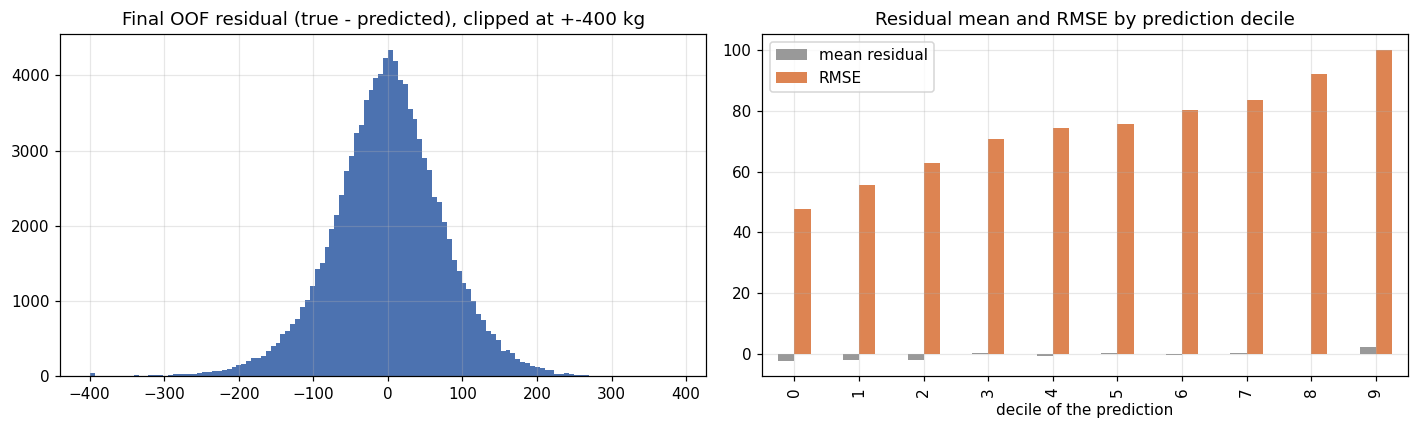

In [12]:
def athlete_key(frame, with_federation=True, extra=()):
    birth = np.floor(frame['MeetYear'] - frame['Age'] + 1e-9).astype(int).astype(str)
    key = frame['Sex'] + '|' + frame['Country'] + '|' + frame['State']
    if with_federation:
        key = key + '|' + frame['Federation']
    key = key + '|' + birth
    for column in extra:
        key = key + '|' + frame[column].astype(str)
    return key.reset_index(drop=True)


def final_residuals():
    v4 = ARTIFACTS / '04_final_model' / 'v4_eight_models'
    before = np.load(v4 / 'oof_nested_blend.npy')        # 8 个模型的嵌套 NNLS 融合
    after = np.load(v4 / 'oof_final_crossfit.npy')       # 再加双胞胎 + S3（交叉拟合）
    require(len(before) == n_train and len(after) == n_train, 'OOF 长度不符')
    r0, r1 = y - before, y - after
    print(f'OOF RMSE：融合 {rmse(y, before):.3f} → 加第二层 {rmse(y, after):.3f}')
    keys_all = pd.concat([athlete_key(train), athlete_key(test)], ignore_index=True)
    appearances = keys_all.map(keys_all.value_counts()).iloc[:n_train].to_numpy()
    appearances = np.where(train['Country'].to_numpy() == 'Unknown', 0, appearances)
    age_half = ((train['Age'] * 2).round() % 2).astype(int).to_numpy()
    largest = train['Federation'].value_counts().head(8).index
    groups = {
        '性别 × 装备': (train['Sex'] + '|' + train['Equipment']).to_numpy(),
        '是否药检赛': train['Tested'].to_numpy(),
        '年龄段': pd.cut(train['Age'], [0, 18, 24, 35, 40, 50, 60, np.inf], right=False).astype(str).to_numpy(),
        '体重段': pd.cut(train['BodyweightKg'], [0, 60, 75, 90, 105, 120, 140, np.inf], right=False).astype(str).to_numpy(),
        '比赛年份': pd.cut(train['MeetYear'], [-np.inf, 2000, 2010, 2015, 2020, np.inf], right=False).astype(str).to_numpy(),
        '联盟（最大的 8 个）': np.where(train['Federation'].isin(largest), train['Federation'], '其他'),
        '年龄是否 x.5': np.where(age_half == 1, 'x.5', '整数'),
        '同一运动员出现次数（train+test）': pd.cut(appearances, [-1, 0, 1, 2, 5, np.inf],
                                                labels=['国籍未知', '1', '2', '3-5', '6+']).astype(str),
    }
    parts = []
    for name, key in groups.items():
        frame = pd.DataFrame({'k': np.asarray(key).astype(str), 'r0': r0, 'r1': r1})
        part = frame.groupby('k').agg(行数=('r1', 'size'), 残差均值_融合=('r0', 'mean'), 残差均值_加第二层=('r1', 'mean'),
                                      RMSE_加第二层=('r1', lambda v: float(np.sqrt(np.mean(np.square(v))))))
        part.index = pd.MultiIndex.from_product([[name], part.index], names=['分组', '取值'])
        parts.append(part)
    display(pd.concat(parts).round(2))

    big = np.abs(r1) > 150
    print(f'|残差| > 150 kg 的行占 {big.mean():.1%}，却占总平方误差的 {np.sum(r1[big] ** 2) / np.sum(r1 ** 2):.0%}')
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].hist(np.clip(r1, -400, 400), bins=120, color='#4c72b0')
    axes[0].set_title('Final OOF residual (true - predicted), clipped at +-400 kg')
    deciles = pd.qcut(after, 10, labels=False, duplicates='drop')
    binned = pd.DataFrame({'d': deciles, 'r': r1}).groupby('d')['r'].agg(
        ['mean', lambda v: float(np.sqrt(np.mean(np.square(v))))])
    binned.columns = ['mean residual', 'RMSE']
    binned.plot.bar(ax=axes[1], color=['#999999', '#dd8452'])
    axes[1].set_xlabel('decile of the prediction')
    axes[1].set_title('Residual mean and RMSE by prediction decile')
    plt.tight_layout()
    plt.show()


final_residuals()

**怎么读**：
- **大多数分组的残差均值在 ±1.5 kg 以内**，模型在这些方向上已经校准。偏差较大的都是小分组或极端分组：
  - 女子多层装备（380 行）+4.3；
  - 体重 ≥ 140 kg +3.9；
  - 60 岁以上 −2.5；
  - 只出现一次的运动员 −1.3。

  Mx 只有 9 行。
- **误差大小差别很大**：女子无装备 RMSE 54 kg，男子多层装备 111 kg；体重越大越难预测。
- **大误差集中在少数极端行**：|残差| > 150 kg 的 5.3% 行占总平方误差的 36%，多为失败或不完整的比赛记录，例如 216 kg 体重的选手总成绩 155 kg。它们无法从特征识别，也不能删掉（第 3 节）。

## 2. 残差的结构：同一运动员、双胞胎 → 第二层

特征描述不了个人训练水平，但训练集里常有**同一个人**的其他成绩。下表是「同一键内其他行的平均残差」与本行残差的相关（留一）。相关大于 0，说明可以借用这个人其他记录的残差来修正预测。

- 早期 v2 的残差上，运动员键的相关约 0.095。
- 最终融合中，H、H2 特征已经吸收了一部分，降到约 0.045。
- 加第二层之后降到约 0，同一运动员的信息基本用完。
- 比赛键本来就接近 0（−0.008）。加第二层后为 0.037：第二层里的比赛项在交叉拟合下带来了少量同场比赛的相关，影响很小。

In [13]:
def athlete_residual_correlation():
    """同一键内「其他行」的平均残差与本行残差的相关（留一）：> 0 说明残差里还有可借用的个人 / 比赛效应。"""
    v4 = ARTIFACTS / '04_final_model' / 'v4_eight_models'
    before = y - np.load(v4 / 'oof_nested_blend.npy')
    after = y - np.load(v4 / 'oof_final_crossfit.npy')
    known = (train['Country'] != 'Unknown').to_numpy()
    keys = {
        'A0 性别 + 国籍 + 州 + 出生年': (athlete_key(train, with_federation=False), known),
        'A1 再加联盟': (athlete_key(train), known),
        'A2 再加装备': (athlete_key(train, extra=['Equipment']), known),
        '比赛 × 性别 × 装备': ((train['Federation'] + '|' + train['MeetYear'].astype(str) + '|' + train['MeetCountry']
                             + '|' + train['MeetState'] + '|' + train['Sex'] + '|' + train['Equipment'])
                            .reset_index(drop=True), np.ones(n_train, dtype=bool)),
    }

    def loo_corr(residual, key, valid):
        frame = pd.DataFrame({'k': key.to_numpy(), 'r': residual})
        total = frame.groupby('k')['r'].transform('sum').to_numpy()
        count = frame.groupby('k')['r'].transform('size').to_numpy()
        mask = valid & (count > 1)
        others = (total - residual) / np.maximum(count - 1, 1)
        return float(np.corrcoef(residual[mask], others[mask])[0, 1]), int(mask.sum())

    rows = []
    for name, (key, valid) in keys.items():
        c0, n0 = loo_corr(before, key, valid)
        c1, _ = loo_corr(after, key, valid)
        rows.append({'键': name, '有同键其他行的训练行': n0, '残差相关：融合后': c0, '残差相关：加第二层后': c1})
    display(pd.DataFrame(rows).set_index('键').round(3))


athlete_residual_correlation()

,有同键其他行的训练行,残差相关：融合后,残差相关：加第二层后
键,,,
A0 性别 + 国籍 + 州 + 出生年,99058,0.048,-0.014
A1 再加联盟,84916,0.044,0.008
A2 再加装备,79779,0.046,0.001
比赛 × 性别 × 装备,97622,-0.008,0.037


第二层就是利用这一点的后处理，全部只用训练标签和 OOF。为了得到诚实的分数，按「性别 + 国籍 + 州」的哈希奇偶分两半交叉拟合：同一个人的所有记录在同一半，一半拟合、另一半评分。

1. **双胞胎**：训练集中 16 列完全相同（exact）或核心 9 列相同（core）的行，把预测往其真实成绩拉：`pred + alpha × (双胞胎均值 − pred)`，exact 的 alpha 约 0.85，core 约 0.5。
2. **同一运动员平滑**：近似同一运动员的其他行的残差，收缩后取平均，线性组合后加到预测上。
   - 键：A0 = 性别 + 国籍 + 州 + 出生年，A1 加联盟，A2 加装备，A3 加级别；另加比赛键。
   - S0 只用精确出生年；S1 允许出生年 ±1；S2 按比赛年份差做时间衰减；S3 三者合并，线性组合；S4 三者合并，用小 LightGBM 组合。

In [14]:
def stage2_history():
    round1 = ARTIFACTS / '02_feature_engineering' / 'round1'
    zoo = ARTIFACTS / '03_model_selection' / 'model_zoo'
    round3 = ARTIFACTS / '02_feature_engineering' / 'round3'
    final = ARTIFACTS / '04_final_model' / 'v4_eight_models'
    print('1) 双胞胎后处理（实验 07，三模型融合）：')
    show(read_summary(round1 / 'summary_twins.csv'))
    print('2) 同一运动员平滑 S0（实验 08）：在实验 08 的堆叠和 v2 上')
    show(read_summary(zoo / 'summary_stage2.csv'),
         ['oof_rmse', 'twins_crossfit', 'twins_athlete_crossfit', 'athlete_gain', 'beta_A0', 'beta_A1', 'beta_A2',
          'beta_A3', 'beta_M2'])
    print('3) 5 种第二层做法（实验 10，ALL3 三模型融合 + 双胞胎之后）：')
    show(read_summary(round3 / 'summary_stage2_variants.csv'))
    print('4) 最终版（实验 15）：')
    show(read_summary(final / 'summary_stage2.csv'))


stage2_history()

1) 双胞胎后处理（实验 07，三模型融合）：


,oof_rmse,oof_rmse_twinfix_crossfit,alpha_exact,alpha_core,test_rows_exact,test_rows_core
name,,,,,,
F0_blend3,77.956,77.701,0.866,0.57,465,54
ALL_blend3_C2,77.210,76.966,0.864,0.54,465,54


2) 同一运动员平滑 S0（实验 08）：在实验 08 的堆叠和 v2 上


,oof_rmse,twins_crossfit,twins_athlete_crossfit,athlete_gain,beta_A0,beta_A1,beta_A2,beta_A3,beta_M2
base,,,,,,,,,
08 五折堆叠（global_nnls）,77.013,76.757,76.521,0.236,0.247,-0.022,0.119,0.193,-0.039
v2（10 折 × 种子，NNLS）,77.302,77.059,76.774,0.285,0.240,-0.036,0.107,0.167,0.482


3) 5 种第二层做法（实验 10，ALL3 三模型融合 + 双胞胎之后）：


,n_features,crossfit_rmse,gain_vs_twins,fold1,fold2,fold3,fold4,fold5
variant,,,,,,,,
S3_all_linear,13,76.510,0.139,76.489,76.677,76.906,76.740,75.733
S2_decay,5,76.527,0.122,76.516,76.688,76.893,76.764,75.770
S0_exact,5,76.539,0.109,76.503,76.693,76.938,76.766,75.792
S1_fuzzy,5,76.544,0.105,76.514,76.707,76.947,76.749,75.799
S4_all_gbm,13,76.858,-0.209,76.890,76.909,77.313,77.104,76.067


4) 最终版（实验 15）：


,oof_rmse
step,
融合（嵌套）,76.319
+ 双胞胎（交叉拟合）,76.097
+ S3 平滑（交叉拟合）,75.966


**结论**：
- 双胞胎在交叉验证上稳定降约 0.22–0.26，公开榜上两次分别 −0.18、−0.19。
- 同一运动员平滑是最有效的一步：实验 08 中 −0.24，公开榜 −0.29 / −0.48。
- 5 种做法中 **S3（精确 + 出生年 ±1 + 时间衰减，线性组合）最好**，S4 的小 LightGBM 过拟合（+0.21）。最终集成用 S3。
- 特征里加入运动员历史（H、H2）之后，平滑的增益从 −0.24 降到 −0.13，两者有重叠，但仍然互补。
- S3 把同组的行同等对待；实验 16–17 改为逐对估计权重（04 第 5 节），在 S3 之后再降 0.39：75.966 → 75.607 → 75.575。

## 3. 数据清洗实验（实验 11）

- 疑似行：男子总成绩 < 2.5 × 体重、女子 < 1.8 × 体重（多为只完成单项或失败的比赛），或年龄 < 5 岁，约 0.25%。
- 做法：种子 42、同样的五折和内层划分，只把疑似行从训练和早停集合中去掉；外层验证仍然用全部行评分，因为测试集里同样有这类行。
- 与 04 中同模型、同种子的结果逐折配对比较；另外单独看「正常行」（非疑似的验证行）上的分数。

In [15]:
def cleaning_test():
    v1 = ARTIFACTS / '04_final_model' / 'v1_six_models'
    ratio = y / train['BodyweightKg'].to_numpy(dtype='float64')
    suspicious = (np.where(train['Sex'].to_numpy() == 'M', ratio < 2.5, ratio < 1.8)
                  | (train['Age'].to_numpy(dtype='float64') < 5))
    print(f'疑似行：{int(suspicious.sum())}（{suspicious.mean():.2%}）')
    rows = []
    for model in ['lgb', 'xgb', 'catboost']:
        base_all, clean_all, base_normal, clean_normal = [], [], [], []
        for k in range(1, N_FOLDS + 1):
            base_path = v1 / f'{model}__s{SEED}__fold{k}.npz'
            clean_path = v1 / f'clean_{model}__s{SEED}__fold{k}.npz'
            if not (base_path.is_file() and clean_path.is_file() and clean_path.with_suffix('.json').is_file()):
                continue                                   # 与实验 11 相同：npz 和 json 都在才算完成
            base, clean = np.load(base_path), np.load(clean_path)
            idx = base['valid_idx']
            require(np.array_equal(idx, clean['valid_idx']), '清洗实验与基线的验证行不一致')
            normal = ~suspicious[idx]
            base_all.append(rmse(y[idx], base['val']))
            clean_all.append(rmse(y[idx], clean['val']))
            base_normal.append(rmse(y[idx][normal], base['val'][normal]))
            clean_normal.append(rmse(y[idx][normal], clean['val'][normal]))
        if base_all:
            delta = np.array(clean_all) - np.array(base_all)
            rows.append({'模型': model, '完成折数': len(base_all), '基线：全部验证行': np.mean(base_all),
                         '去掉疑似行训练：全部验证行': np.mean(clean_all), 'Δ': delta.mean(),
                         '更好折数': int((delta < 0).sum()), '基线：只看正常行': np.mean(base_normal),
                         '去掉疑似行训练：只看正常行': np.mean(clean_normal)})
    if rows:
        display(pd.DataFrame(rows).set_index('模型').round(3))


cleaning_test()

疑似行：265（0.25%）


,完成折数,基线：全部验证行,去掉疑似行训练：全部验证行,Δ,更好折数,基线：只看正常行,去掉疑似行训练：只看正常行
模型,,,,,,,
lgb,5,77.708,77.751,0.043,2,76.821,76.787
xgb,5,78.457,78.519,0.063,2,77.545,77.519
catboost,5,77.497,77.577,0.081,1,76.627,76.620


**结论**：去掉疑似行后，三个模型在全部验证行上都**变差**（+0.04 到 +0.08，最多 2/5 折更好）；只看正常行时略好 0.01–0.03 kg。测试集里同样有这类失败记录，按全部行评分时删掉它们得不偿失，所以全部保留，不删除也不截尾。

## 4. 没有成功的方向

| 方向 | 结果 | 在哪里 |
|---|---|---|
| 基于成绩的嵌套特征：运动员实力、比赛实力 | +0.14 / +0.52，公开榜也变差 | 02 第四轮 |
| 比赛背景加强、组别背景、DOTS 系数（对三模型融合） | +0.00 到 +0.05 | 02 第二轮 |
| 跨地参赛 `T` 单独 | −0.04，未达标 | 02 第一轮 |
| 粗粒度目标编码（性别 × 装备 × 级别等） | +0.27，变差 | 早期 pipeline |
| 频次特征、性别 × 装备交互、近似出生年 | ±0.05 以内 | 早期 pipeline |
| TabPFN、随机森林、ExtraTrees、EBM、Ridge | 单独差 3–7 kg，融合权重 0 | 03 第 5 节 |
| 分段 NNLS、残差元模型（堆叠） | 不如全局 NNLS | 03 第 3 节 |
| 第二层用小 LightGBM（S4） | 过拟合 +0.21 | 本 notebook 第 2 节 |
| 训练时删除疑似错误的成绩 | +0.04 到 +0.08 | 本 notebook 第 3 节 |
| id 作为特征 | id 顺序随机，没有信息 | 01 第 7 节 |
| log 目标 | 预测几何均值，对 kg 的 RMSE 系统偏低，没有采用 | — |
| 外部数据（OpenPowerlifting 原始库） | 测试行就在其中，等于标签泄漏，禁止使用 | — |

## 5. 交叉验证与公开榜

下面的图比较所有有交叉验证分数的提交。实验 07 起改用内层早停后，公开榜与交叉验证的顺序基本一致；v1、v2 用外层验证折早停，交叉验证偏乐观。

第二部分用 OOF 模拟公开榜：随机抽 13,500 行，看最终两个候选 v4 与 v3_plus 的差异有多大可能在公开榜上反过来。

,cv,public,public - cv
submission,,,
v1,77.775,78.000,0.225
v2,77.302,77.799,0.497
v2 + twins,77.060,77.604,0.544
07 F0 + twins,77.701,77.947,0.246
07 ALL + C2,77.210,77.337,0.127
07 ALL + C2 + twins,76.966,77.158,0.192
08 stack,77.013,77.207,0.194
08 + twins,76.757,77.018,0.261
08 + twins + athlete,76.521,76.731,0.210


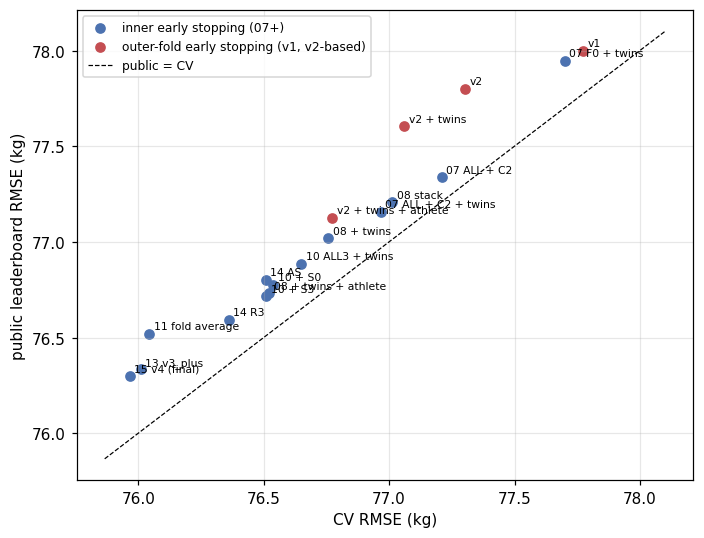

实验 07 起（内层早停）公开榜与 CV 的 Spearman 相关：0.97
全部 105,000 行：v4 75.966，v3_plus 76.010，差 -0.045
随机 13,500 行：单个提交的 RMSE 标准差 0.588；两者之差的标准差 0.026；公开榜上 v4 反而显示更差的概率 4%
实际公开榜：v4 比 v3_plus -0.036


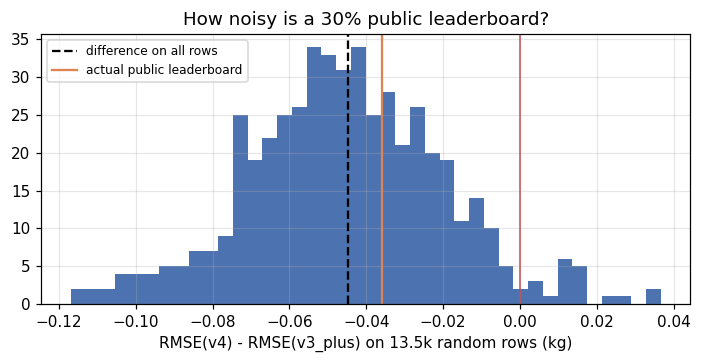

In [16]:
def leaderboard_analysis():
    history = pd.DataFrame([
        ('v1', 77.775, 78.0), ('v2', 77.302, 77.799), ('v2 + twins', 77.060, 77.604),
        ('07 F0 + twins', 77.701, 77.947), ('07 ALL + C2', 77.210, 77.337), ('07 ALL + C2 + twins', 76.966, 77.158),
        ('08 stack', 77.013, 77.207), ('08 + twins', 76.757, 77.018), ('08 + twins + athlete', 76.521, 76.731),
        ('v2 + twins + athlete', 76.774, 77.125), ('10 ALL3 + twins', 76.649, 76.884),
        ('10 + S0', 76.539, 76.775), ('10 + S3', 76.510, 76.716), ('11 fold average', 76.044, 76.520),
        ('13 v3_plus', 76.010, 76.334), ('14 R3', 76.361, 76.592), ('14 AS', 76.508, 76.802),
        ('15 v4 (final)', 75.966, 76.298),
    ], columns=['submission', 'cv', 'public'])
    history['public - cv'] = history['public'] - history['cv']
    display(history.set_index('submission').round(3))
    early = history['submission'].isin(['v1', 'v2', 'v2 + twins', 'v2 + twins + athlete'])   # 外层折早停
    fig, ax = plt.subplots(figsize=(6.5, 5))
    ax.scatter(history.loc[~early, 'cv'], history.loc[~early, 'public'], color='#4c72b0', label='inner early stopping (07+)')
    ax.scatter(history.loc[early, 'cv'], history.loc[early, 'public'], color='#c44e52', label='outer-fold early stopping (v1, v2-based)')
    for _, row in history.iterrows():
        ax.annotate(row['submission'], (row['cv'], row['public']), fontsize=7, xytext=(3, 3), textcoords='offset points')
    lims = [history[['cv', 'public']].min().min() - 0.1, history[['cv', 'public']].max().max() + 0.1]
    ax.plot(lims, lims, color='black', lw=0.8, ls='--', label='public = CV')
    ax.set_xlabel('CV RMSE (kg)')
    ax.set_ylabel('public leaderboard RMSE (kg)')
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()
    print(f"实验 07 起（内层早停）公开榜与 CV 的 Spearman 相关："
          f"{history.loc[~early, ['cv', 'public']].corr(method='spearman').iloc[0, 1]:.2f}")


def public_noise():
    """用 OOF 模拟公开榜：随机抽 13,500 行（≈ 测试集的 30%），比较 v4 与 v3_plus。"""
    v3 = np.load(ARTIFACTS / '03_model_selection' / 'model_compare' / 'oof_final_crossfit.npy')
    v4 = np.load(ARTIFACTS / '04_final_model' / 'v4_eight_models' / 'oof_final_crossfit.npy')
    rng = np.random.default_rng(SEED)
    single, diff = [], []
    for _ in range(500):
        idx = rng.choice(n_train, 13500, replace=False)
        a, b = rmse(y[idx], v3[idx]), rmse(y[idx], v4[idx])
        single.append(b)
        diff.append(b - a)
    diff = np.array(diff)
    public_gap = 76.298 - 76.334                       # 实际公开榜：v4 76.298，v3_plus 76.334
    print(f'全部 105,000 行：v4 {rmse(y, v4):.3f}，v3_plus {rmse(y, v3):.3f}，差 {rmse(y, v4) - rmse(y, v3):+.3f}')
    print(f'随机 13,500 行：单个提交的 RMSE 标准差 {np.std(single):.3f}；两者之差的标准差 {np.std(diff):.3f}；'
          f'公开榜上 v4 反而显示更差的概率 {np.mean(diff > 0):.0%}')
    print(f'实际公开榜：v4 比 v3_plus {public_gap:+.3f}')
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    ax.hist(diff, bins=40, color='#4c72b0')
    ax.axvline(rmse(y, v4) - rmse(y, v3), color='black', ls='--', label='difference on all rows')
    ax.axvline(public_gap, color='#dd8452', lw=1.5, label='actual public leaderboard')
    ax.axvline(0, color='#c44e52', lw=1)
    ax.set_xlabel('RMSE(v4) - RMSE(v3_plus) on 13.5k random rows (kg)')
    ax.set_title('How noisy is a 30% public leaderboard?')
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


leaderboard_analysis()
public_noise()

**结论**：
- **排序可信**：实验 07 起（内层早停），公开榜与交叉验证的排序相关 0.97。公开榜一致地比交叉验证高，大多高 0.2–0.3 kg，实验 11 的折平均版高 0.48；用外层折早停的 v2 系列高 0.35–0.54。
- **偏移来自公开榜那 30% 行**：在随机 13,500 行上，单个提交的 RMSE 标准差约 0.59 kg，而两个相近提交之差的标准差只有约 0.03 kg。公开榜对所有提交都用同一批行，所以它们共享同一个偏移。比较两个提交时，看差值是可靠的，看绝对值则不可靠。
- **最终两个候选**：v4 在交叉验证上比 v3_plus 好 0.045，模拟中在公开榜上反过来的概率约 4%；实际公开榜上 v4 好 0.036，与预期一致。

## 6. 结论

- **最有效的方向**：
  - 发现数据结构：双胞胎、同一运动员的其他成绩、记录精度；
  - 让模型看到「比赛级别」和「这个人是谁」的特征；
  - 多种子与全量重训。
- **相对力量目标**：DOTS、IPF GL 的 CatBoost 是最强的单模型，与 kg 目标的模型互补。
- **饱和**：不看成绩的特征到第三轮基本饱和；基于成绩的特征放进模型反而变差，放在模型之后的平滑里效果更好。
- **选模**：公开榜只有 30% 的测试数据，所以选模以五折交叉验证和同协议的配对比较为准；公开榜只作确认，两者的排序一致。
- **最终结果**：v4 的五折交叉验证 75.966，公开榜 76.298；加两步成对平滑后 75.575 / 76.030（04 第 5 节）。起点 v1 的交叉验证为 77.775，公开榜 78.0。